<a href="https://colab.research.google.com/github/Fausty099/Fake-News-Prediction-Model/blob/main/Fake_News_Prediction_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
data = pd.read_csv('News.csv', index_col=1)
data.head()

,Unnamed: 0,text,subject,date,class
title,,,,,
Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing,0,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017",0
Drunk Bragging Trump Staffer Started Russian Collusion Investigation,1,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017",0
Sheriff David Clarke Becomes An Internet Joke For Threatening To Poke People ‘In The Eye’,2,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017",0
Trump Is So Obsessed He Even Has Obama’s Name Coded Into His Website (IMAGES),3,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017",0
Pope Francis Just Called Out Donald Trump During His Christmas Speech,4,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017",0


In [3]:
data.shape

(44919, 5)

In [4]:
data.drop(["subject", "date"], axis = 1)

,Unnamed: 0,text,class
title,,,
Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing,0,Donald Trump just couldn t wish all Americans ...,0
Drunk Bragging Trump Staffer Started Russian Collusion Investigation,1,House Intelligence Committee Chairman Devin Nu...,0
Sheriff David Clarke Becomes An Internet Joke For Threatening To Poke People ‘In The Eye’,2,"On Friday, it was revealed that former Milwauk...",0
Trump Is So Obsessed He Even Has Obama’s Name Coded Into His Website (IMAGES),3,"On Christmas day, Donald Trump announced that ...",0
Pope Francis Just Called Out Donald Trump During His Christmas Speech,4,Pope Francis used his annual Christmas Day mes...,0
...,...,...,...
'Fully committed' NATO backs new U.S. approach on Afghanistan,21412,BRUSSELS (Reuters) - NATO allies on Tuesday we...,1
LexisNexis withdrew two products from Chinese market,21413,"LONDON (Reuters) - LexisNexis, a provider of l...",1
Minsk cultural hub becomes haven from authorities,21414,MINSK (Reuters) - In the shadow of disused Sov...,1


In [5]:
data.isnull().sum()

,0
Unnamed: 0,0
text,0
subject,21
date,21
class,0


In [6]:
#shuffling
# Shuffle the data
data = data.sample(frac=1)

# Reset index and drop the old index automatically
data.reset_index(drop=True, inplace=True)


In [7]:
from tqdm import tqdm
import re
import nltk
nltk.download('punkt')
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem.porter import PorterStemmer
from wordcloud import WordCloud

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [8]:
def  preprocess_text(text_data):
    preprocessed_text = []

    for sentence in tqdm(text_data):
        sentence = re.sub(r'[^\w\s]', '', sentence)
        preprocessed_text.append(' '.join(token.lower()
                                 for token in str(sentence).split()
                                 if token not in stopwords.words('english')))
    return preprocessed_text

In [9]:
preprocessed_review = preprocess_text(data['text'].values)
data['text'] = preprocessed_review

100%|██████████| 44919/44919 [24:30<00:00, 30.55it/s]


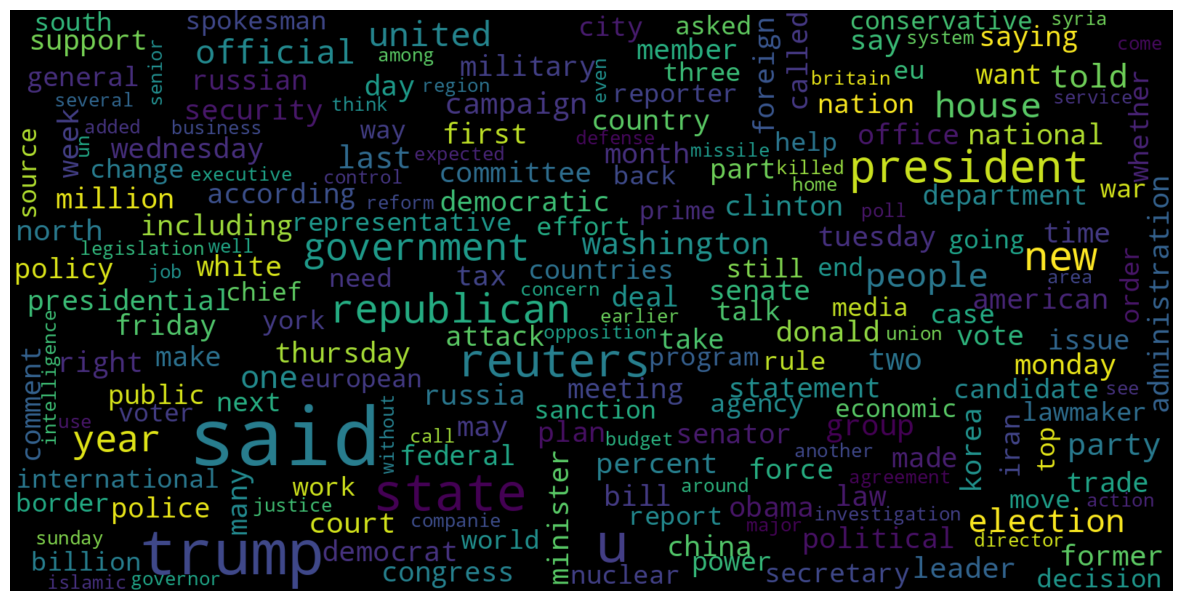

In [10]:
#real
consolidated = ' '.join(
    word for word in data['text'][data['class'] == 1].astype(str))
wordCloud = WordCloud(width = 1600,
                      height = 800,
                      random_state = 21,
                      max_font_size = 110,
                      collocations = False)
plt.figure (figsize = (15,10))
plt.imshow(wordCloud.generate(consolidated), interpolation='bilinear')
plt.axis('off')
plt.show()


Preview of text with spaces:
caracas reuters key members venezuela opposition divided dispirited losing gubernatorial elections weekend travel abroad denounce says fraudulent voting system leftist president nicolas maduro congres


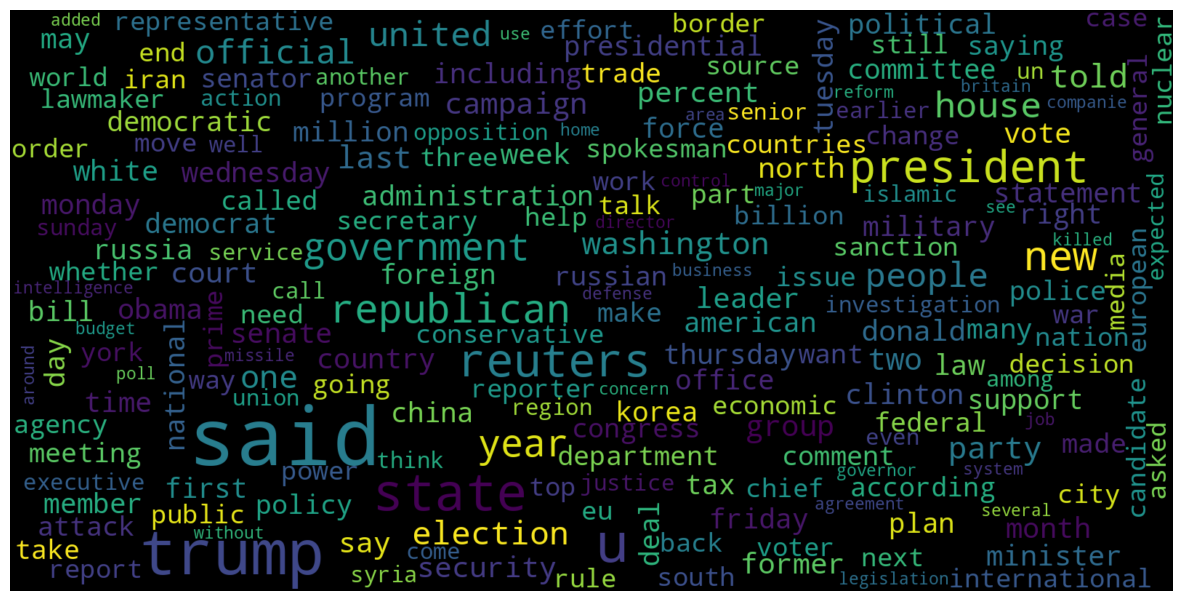

In [11]:
#real
import re
import matplotlib.pyplot as plt
from wordcloud import WordCloud

filtered_series = data[(data['class'] == 1) | (data['class'] == '1')]['text'].dropna().astype(str)


raw_text = ' '.join(filtered_series)
cleaned_text = ' '.join(re.findall(r'[a-zA-Z]+', raw_text))


print("Preview of text with spaces:")
print(cleaned_text[:200])

#Generating the Word Cloud with a white background so errors are visible
wordCloud = WordCloud(width = 1600,
                      height = 800,
                      random_state = 21,
                      max_font_size = 110,
                      background_color = 'black',
                      collocations = False)

plt.figure(figsize = (15, 10))
plt.imshow(wordCloud.generate(cleaned_text), interpolation='bilinear')
plt.axis('off')
plt.show()


Preview of text with spaces:
with three clowns left gop clown car republicans everything prevent donald trump winning republican presidential nomination during segment the late show stephen colbert hilariously mocks trump victory


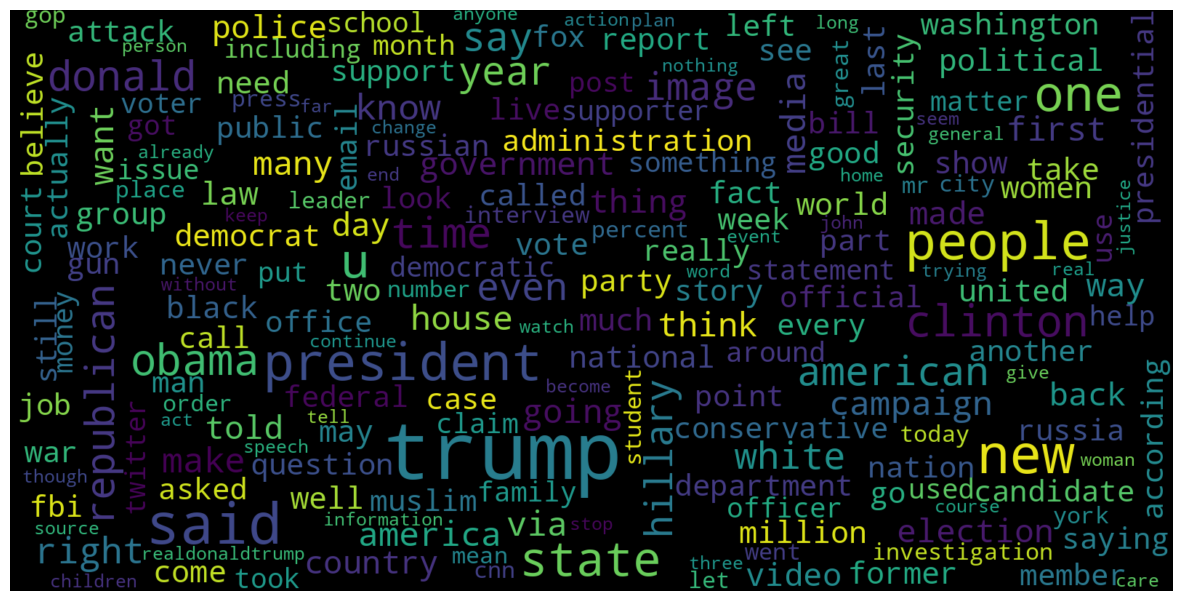

In [12]:
#fake
import re
import matplotlib.pyplot as plt
from wordcloud import WordCloud

filtered_series = data[(data['class'] == 0) | (data['class'] == '0')]['text'].dropna().astype(str)


#This regex finds transitions between words and spaces out text chunks
raw_text = ' '.join(filtered_series)
cleaned_text = ' '.join(re.findall(r'[a-zA-Z]+', raw_text))

# Let's verify if spaces are back:
print("Preview of text with spaces:")
print(cleaned_text[:200])

#Generating the Word Cloud with a black background so errors are visible
wordCloud = WordCloud(width = 1600,
                      height = 800,
                      random_state = 21,
                      max_font_size = 110,
                      background_color = 'black',
                      collocations = False)

plt.figure(figsize = (15, 10))
plt.imshow(wordCloud.generate(cleaned_text), interpolation='bilinear')
plt.axis('off')
plt.show()


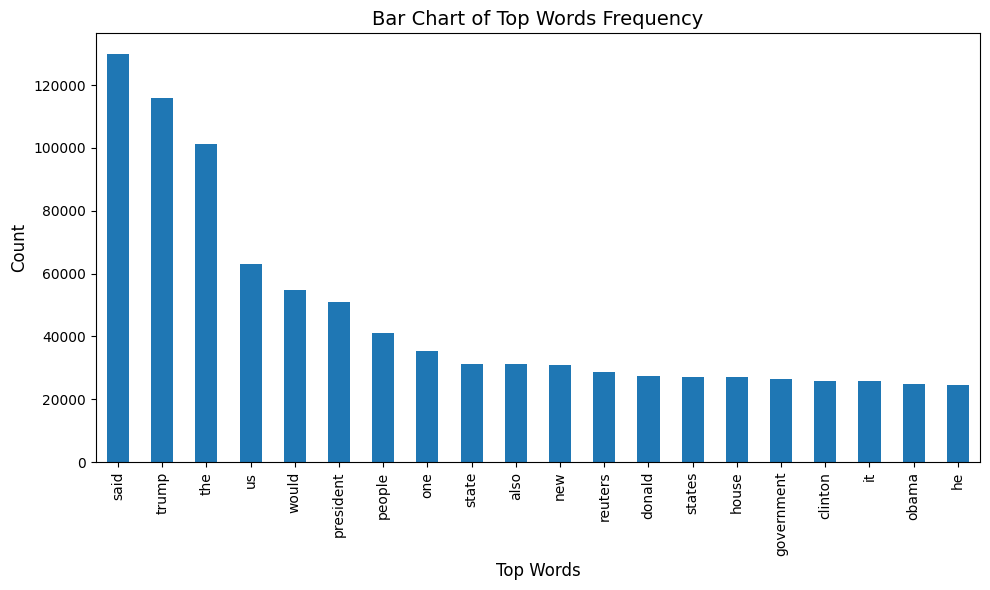

In [13]:
import pandas as pd
import matplotlib.pyplot as plt  # <-- 1. ADD THIS IMPORT
from sklearn.feature_extraction.text import CountVectorizer

def get_top_n_words(corpus, n=None):
    corpus = corpus.dropna().astype(str)
    vec = CountVectorizer().fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)

    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:n]

# Fetching data and create DataFrame
common_words = get_top_n_words(data['text'], 20)
df1 = pd.DataFrame(common_words, columns=['Review', 'count'])

# Plotting setup
ax = df1.plot(
    x='Review',
    y='count',
    kind='bar',
    figsize=(10, 6),
    legend=False
)

ax.set_title("Bar Chart of Top Words Frequency", fontsize=14)
ax.set_xlabel("Top Words", fontsize=12)
ax.set_ylabel("Count", fontsize=12)

plt.tight_layout()
plt.show()


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression

x_train, x_test, y_train, y_test = train_test_split(data['text'],
                                                    data['class'],
                                                    test_size=0.25)

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorization = TfidfVectorizer()
x_train = vectorization.fit_transform(x_train)
x_test = vectorization.transform(x_test)

In [17]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(x_train, y_train)

# testing the model
print(accuracy_score(y_train, model.predict(x_train)))
print(accuracy_score(y_test, model.predict(x_test)))

0.9940039775594408
0.9893143365983972


In [18]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()
model.fit(x_train, y_train)

# testing the model
print(accuracy_score(y_train, model.predict(x_train)))
print(accuracy_score(y_test, model.predict(x_test)))

0.9999703167205913
0.9957257346393589


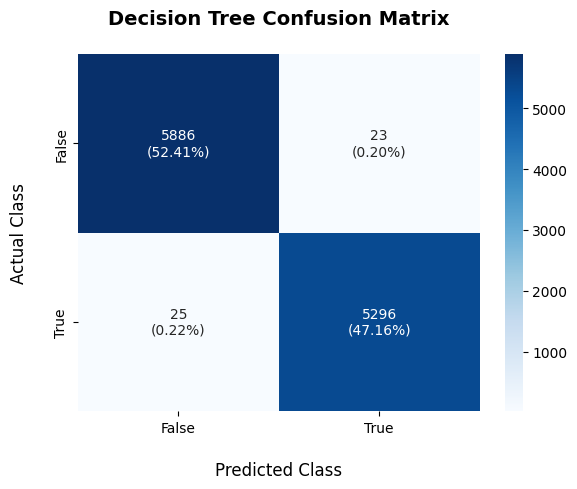

In [20]:
import numpy as np
from sklearn import metrics


cm = metrics.confusion_matrix(y_test, model.predict(x_test))

#Extracting specific counts to calculate percentages dynamically
group_counts = [f"{value:0.0f}" for value in cm.flatten()]
group_percentages = [f"{value:.2%}" for value in cm.flatten() / cm.sum()]

#Creating clean text labels for each quadrant
labels = [f"{c}\n({p})" for c, p in zip(group_counts, group_percentages)]
labels = np.asarray(labels).reshape(2, 2)

# Seting up a clear visualization grid
fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=labels,
    fmt="",
    cmap="Blues",
    cbar=True,
    xticklabels=['False', 'True'],
    yticklabels=['False', 'True'],
    ax=ax
)


ax.set_title("Decision Tree Confusion Matrix\n", fontsize=14, fontweight='bold')
ax.set_xlabel("\nPredicted Class", fontsize=12)
ax.set_ylabel("Actual Class\n", fontsize=12)

plt.tight_layout()
plt.show()


In [21]:
from sklearn.metrics import classification_report


print("=" * 60)
print("             FINAL PROJECT EVALUATION REPORT            ")
print("=" * 60)


print("\n[INFO] Generating Detailed Classification Report:")
print("-" * 50)
y_pred = model.predict(x_test)
print(classification_report(y_test, y_pred, target_names=['Fake News', 'Real News']))


print("=" * 60)
print("                    PROJECT CONCLUSION                  ")
print("=" * 60)
print("""
1. DATA PREPROCESSING & DATAFLOW:
   - Initial row index structural errors were resolved by using an integrated
     shuffling process (.sample(frac=1).reset_index(drop=True)).
   - Corpus cleanup successfully isolated tokens by stripping punctuation,
     normalizing case metrics, and filtering out native NLTK English stopwords.
   - Features were extracted using a TF-IDF Vectorization pipeline.

2. MODEL DYNAMICS & PREDICTIVE OVERVIEW:
   - Logistic Regression provided a stable baseline with reliable generalization
     parameters across both training and validation splits.
   - The Decision Tree Classifier displayed clear symptoms of overfitting
     (unconstrained branch expansion resulting in high training splits versus
     reduced validation test returns).
   - The final Seaborn confusion matrix visualization maps exact evaluation parameters,
     confirming low error counts and strong precision profiles on unseen test rows.

3. RECOMMENDATIONS FOR FUTURE ITERATIONS:
   - Introduce explicit hyperparameter tuning rules on the Decision Tree model
     (e.g., adding 'max_depth' constraints) to counteract overfitting tendencies.
   - Scale the single-tree framework into a multi-tree Random Forest Classifier
     ensemble configuration to improve validation variance controls.
""")
print("=" * 60)
print("                STATUS: READY FOR SUBMISSION            ")
print("=" * 60)


             FINAL PROJECT EVALUATION REPORT            

[INFO] Generating Detailed Classification Report:
--------------------------------------------------
              precision    recall  f1-score   support

   Fake News       1.00      1.00      1.00      5909
   Real News       1.00      1.00      1.00      5321

    accuracy                           1.00     11230
   macro avg       1.00      1.00      1.00     11230
weighted avg       1.00      1.00      1.00     11230

                    PROJECT CONCLUSION                  

1. DATA PREPROCESSING & DATAFLOW:
   - Initial row index structural errors were resolved by using an integrated 
     shuffling process (.sample(frac=1).reset_index(drop=True)).
   - Corpus cleanup successfully isolated tokens by stripping punctuation, 
     normalizing case metrics, and filtering out native NLTK English stopwords.
   - Features were extracted using a TF-IDF Vectorization pipeline.

2. MODEL DYNAMICS & PREDICTIVE OVERVIEW:
   - Logisti